# 08 - Línea base: LSTM unidireccional + CTC (y GRU como ablación)

Responsable: Daniela Ramírez de León

La línea base es el modelo recurrente más simple que puede resolver la tarea: una proyección lineal de cada cuadro
y una LSTM que lee la secuencia solo hacia adelante, entrenada con CTC. Sirve como punto de referencia: si un modelo
más complejo no le gana, su complejidad no se justifica. La GRU unidireccional es una ablación: misma arquitectura y
mismos hiperparámetros, cambiando solo la celda, para medir si la LSTM aporta algo frente a una celda más liviana.

Se usa la misma base que el resto del equipo (06_preparacion_modelado): mismo split por participante, mismo
preprocesamiento, mismo loop de entrenamiento y misma métrica (CER).

In [1]:
import sys
sys.path.append("..")

import json

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import dataset, train
from src.models import lstm, gru

sns.set_theme(style="whitegrid")
FIGS = "../reports/figures"
COLORES = {"lstm": "#3B6EA8", "gru": "#8E6BBF"}  # mismos de app/utils.py
CONSTRUCTORES = {"lstm": lstm.construir, "gru": gru.construir}
train.fijar_semilla(42)

## 1. Por qué esta línea base

La revisión bibliográfica ubica a las redes recurrentes como el primer enfoque para transcribir secuencias de
gestos (Graves et al., 2006; Hochreiter y Schmidhuber, 1997). La línea base conserva solo lo indispensable:

- Una capa lineal con LayerNorm y GELU convierte los 227 valores de cada cuadro (manos, pose y máscara de detección) en un vector oculto.
- Un promedio cada stride cuadros (4 en la variante elegida) acorta la secuencia (mediana de 147 cuadros, cola hasta ~750) sin agregar parámetros.
- Una LSTM unidireccional: cada letra se decide solo con lo que ya pasó. Es la diferencia clave contra el CNN-BiGRU y la BiLSTM, que también miran hacia adelante.
- Pérdida CTC, porque la etiqueta es la frase completa sin alineación cuadro a letra.

La GRU (Cho et al., 2014) tiene dos compuertas en lugar de tres, así que usa un 25 % menos de parámetros en la parte
recurrente. Chung et al. (2014) encontraron desempeño parecido entre ambas; aquí se comprueba con estos datos.

## 2. Arquitectura

x (B, T, 227) -> Linear + LayerNorm + GELU -> promedio cada stride cuadros -> LSTM o GRU (unidireccional) -> Linear -> log_softmax (B, T/stride, 60)

Como la red solo lee hacia adelante, el relleno al final de las secuencias cortas no cambia las salidas válidas, así
que no hace falta empaquetarlas. Se revisa la forma de la salida con un lote de validación.

In [2]:
loaders = dataset.crear_dataloaders(batch_size=32, max_frames=384)
x, x_len, y, y_len = next(iter(loaders["val"]))

for nombre, construir in CONSTRUCTORES.items():
    modelo = construir()
    log_probs, out_len = modelo(x, x_len)
    print(f"{nombre}: entrada {tuple(x.shape)} -> salida {tuple(log_probs.shape)}, "
          f"{train.n_parametros(modelo):,} parametros")
print("largos de entrada:", x_len[:6].tolist())
print("largos de salida: ", out_len[:6].tolist())

lstm: entrada (32, 384, 227) -> salida (32, 96, 60), 648,636 parametros
gru: entrada (32, 384, 227) -> salida (32, 96, 60), 500,412 parametros
largos de entrada: [127, 343, 91, 173, 70, 167]
largos de salida:  [32, 86, 23, 44, 18, 42]


## 3. Ajuste de hiperparámetros

Igual que en el modelo principal, se parte de una configuración base y se cambia un hiperparámetro a la vez. Las
variantes son las mismas para la LSTM y la GRU, así la comparación entre celdas es justa. Test no se usa para escoger.

Se usa la misma configuración de entrenamiento que los otros modelos (60 épocas, AdamW con one-cycle, learning rate
0.003), con una diferencia: el early stopping se desactiva (paciencia de 60 épocas). En una primera corrida con
paciencia 10 y stride 2, la LSTM seguía en la fase en la que CTC solo predice blanks después de 10 épocas sin mejora y
se detuvo con CER de 1.0; con las 60 épocas completas llegó apenas a 0.836. Un modelo que solo lee hacia adelante
tarda más en salir de esa fase, así que cortarlo antes no sería una comparación justa. Igual se conservan los pesos
de la época con menor CER de validación.

Esa misma corrida mostró que el stride importa mucho para la línea base: con stride 4 la LSTM ya había llegado a 0.631.
Por eso la base usa stride 4 y stride 2 queda como variante.

- base: 192 unidades, 2 capas, stride 4, dropout 0.3.
- stride_2: secuencias dos veces más largas para la red recurrente.
- mas_capacidad: 256 unidades y 3 capas.
- dropout_0.1: menos regularización, que en el Transformer aceleró el aprendizaje.

In [3]:
BASE = {"hidden": 192, "capas": 2, "stride": 4, "dropout": 0.3}
CONFIG_ENTRENAMIENTO = {"epochs": 60, "lr": 3e-3, "paciencia": 60}  # sin early stopping
VARIANTES = {
    "base": {},
    "stride_2": {"stride": 2},
    "mas_capacidad": {"hidden": 256, "capas": 3},
    "dropout_0.1": {"dropout": 0.1},
}

In [4]:
corridas, mejores = {}, {}
for celda, construir in CONSTRUCTORES.items():
    corridas[celda] = []
    for variante, cambio in VARIANTES.items():
        hp = {**BASE, **cambio}
        train.fijar_semilla(42)
        modelo = construir(**hp)
        print(f"--- {celda} {variante}: {cambio or 'base'} ({train.n_parametros(modelo):,} parametros)")
        resultado = train.fit(modelo, loaders["train"], loaders["val"], CONFIG_ENTRENAMIENTO)
        corridas[celda].append({"variante": variante, "hiperparametros": hp, "n_parametros": train.n_parametros(modelo),
                                "mejor_cer_val": resultado["mejor_cer_val"], "epocas": resultado["epocas"],
                                "tiempo_s": resultado["tiempo_entrenamiento_s"], "historial": resultado["historial"]})
        if celda not in mejores or resultado["mejor_cer_val"] < mejores[celda][2]["mejor_cer_val"]:
            mejores[celda] = (variante, modelo, resultado, hp)
    with open(train.METRICS_DIR / f"{celda}_tuning.json", "w", encoding="utf-8") as f:
        json.dump(corridas[celda], f, ensure_ascii=False, indent=2)

--- lstm base: base (648,636 parametros)


epoca   1 | train 5.963 | val 3.835 | CER 1.000


epoca   2 | train 3.695 | val 3.592 | CER 1.000


epoca   3 | train 3.526 | val 3.525 | CER 1.000


epoca   4 | train 3.495 | val 3.515 | CER 1.000


...

epoca  56 | train 0.613 | val 2.835 | CER 0.616


epoca  57 | train 0.609 | val 2.843 | CER 0.615


epoca  58 | train 0.606 | val 2.845 | CER 0.617


epoca  59 | train 0.605 | val 2.846 | CER 0.615


epoca  60 | train 0.605 | val 2.846 | CER 0.616


In [5]:
tabla = pd.concat([pd.DataFrame(c).assign(celda=celda) for celda, c in corridas.items()])
tabla["tiempo_min"] = (tabla["tiempo_s"] / 60).round(1)
tabla.pivot(index="variante", columns="celda", values=["mejor_cer_val", "n_parametros", "epocas", "tiempo_min"]).round(3)

mejor_cer_val        n_parametros            epocas        \
celda                   gru   lstm          gru       lstm    gru  lstm   
variante                                                                  
base                  0.598  0.631     500412.0   648636.0   60.0  60.0   
dropout_0.1           0.610  0.624     500412.0   648636.0   60.0  60.0   
mas_capacidad         0.637  0.737    1258556.0  1653308.0   60.0  60.0   
stride_2              0.678  0.770     500412.0   648636.0   60.0  60.0   

              tiempo_min       
celda                gru lstm  
variante                       
base                 5.4  3.9  
dropout_0.1          5.1  4.1  
mas_capacidad        9.8  7.4  
stride_2             9.6  5.9

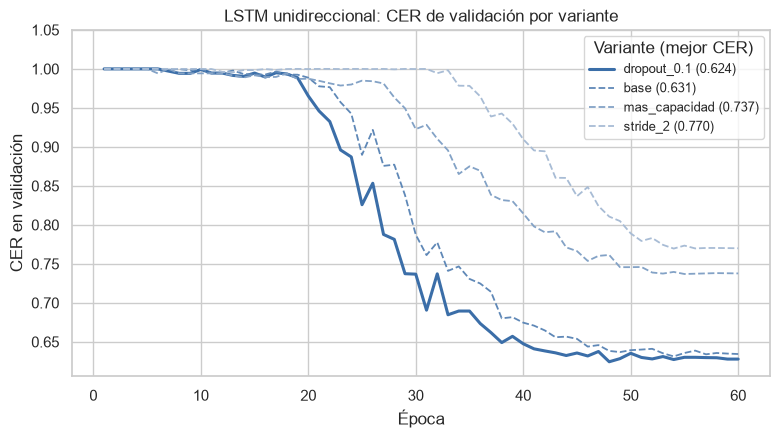

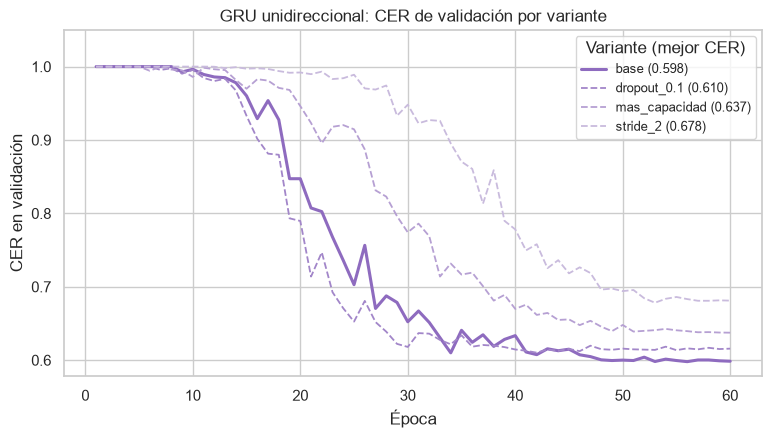

In [6]:
for celda, c_celda in corridas.items():
    elegida = mejores[celda][0]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    tonos = sns.light_palette(COLORES[celda], len(c_celda) + 2)[2:][::-1]
    for color, c in zip(tonos, sorted(c_celda, key=lambda c: c["mejor_cer_val"])):
        elegido = c["variante"] == elegida
        ax.plot(range(1, len(c["historial"]["val_cer"]) + 1), c["historial"]["val_cer"], "-" if elegido else "--",
                color=color, lw=2.2 if elegido else 1.3, label=f"{c['variante']} ({c['mejor_cer_val']:.3f})")
    ax.set(xlabel="Época", ylabel="CER en validación", ylim=(None, 1.05),
           title=f"{celda.upper()} unidireccional: CER de validación por variante")
    ax.legend(title="Variante (mejor CER)", fontsize=9)
    fig.savefig(f"{FIGS}/08_{celda}_tuning.png", dpi=150, bbox_inches="tight")
    plt.show()

## 4. Modelos finales y evaluación en test

Se guarda la mejor variante de cada celda con train.guardar_resultados, que la evalúa en validación y test y escribe
models/lstm.pt, models/gru.pt, reports/metrics/lstm.json y reports/metrics/gru.json (el formato común que leen la
app, la presentación y el notebook 11 de comparación).

In [7]:
reportes = {}
for celda, (variante, modelo, resultado, hp) in mejores.items():
    print(celda, "-> variante elegida:", variante, hp)
    reportes[celda] = train.guardar_resultados(celda, modelo, hp, resultado, loaders)

pd.DataFrame({c: {k: r[k] for k in ["cer_val", "cer_test", "score_kaggle_test", "n_parametros", "epocas",
                                    "tiempo_entrenamiento_s", "ms_por_secuencia"]} for c, r in reportes.items()}).round(3)

lstm -> variante elegida: dropout_0.1 {'hidden': 192, 'capas': 2, 'stride': 4, 'dropout': 0.1}


lstm: CER val 0.624 | CER test 0.566 | 0.7 ms/secuencia
gru -> variante elegida: base {'hidden': 192, 'capas': 2, 'stride': 4, 'dropout': 0.3}


gru: CER val 0.598 | CER test 0.537 | 0.9 ms/secuencia


,lstm,gru
cer_val,0.624,0.598
cer_test,0.566,0.537
score_kaggle_test,0.434,0.463
n_parametros,648636.000,500412.000
epocas,60.000,60.000
tiempo_entrenamiento_s,243.610,321.200
ms_por_secuencia,0.734,0.895


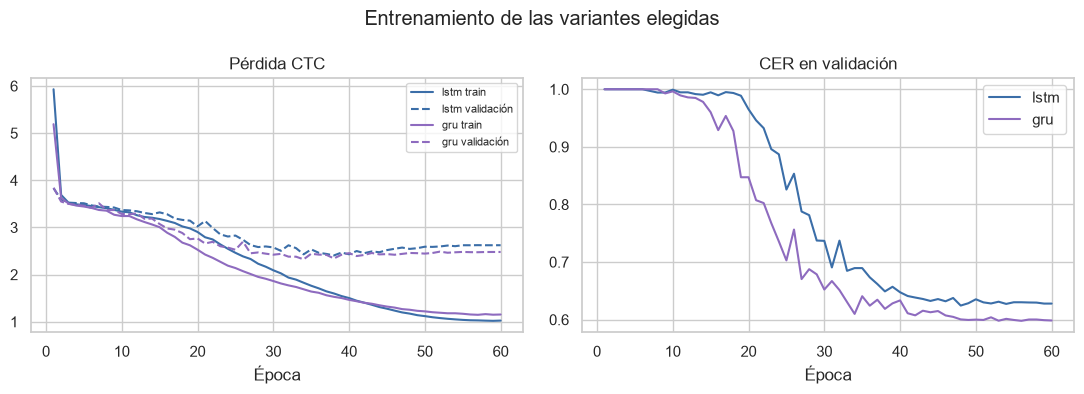

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for celda, r in reportes.items():
    h = r["historial"]
    epocas = range(1, len(h["train_loss"]) + 1)
    axes[0].plot(epocas, h["train_loss"], color=COLORES[celda], label=f"{celda} train")
    axes[0].plot(epocas, h["val_loss"], "--", color=COLORES[celda], label=f"{celda} validación")
    axes[1].plot(epocas, h["val_cer"], color=COLORES[celda], label=celda)
axes[0].set(title="Pérdida CTC", xlabel="Época")
axes[1].set(title="CER en validación", xlabel="Época")
axes[0].legend(fontsize=8)
axes[1].legend()
fig.suptitle("Entrenamiento de las variantes elegidas")
fig.tight_layout()
fig.savefig(f"{FIGS}/08_lstm_gru_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Conclusiones de la línea base

- Ajuste: lo que más pesa en un modelo que solo lee hacia adelante es el largo de la secuencia. Con stride 2 la LSTM tardó más de 30 épocas en salir de la fase de blanks y terminó en 0.770 de CER de validación; con stride 4 bajó a 0.631. Agregar capacidad (256 unidades, 3 capas) empeoró el resultado (0.737), porque con 1,315 secuencias el modelo más grande aprende más lento. Bajar el dropout a 0.1 dio la mejor LSTM (0.624).
- La GRU respondió igual al ajuste (stride 4 y tamaño base fueron lo mejor), pero con dropout 0.3 (0.598); con 0.1 quedó muy cerca (0.610).
- Ablación LSTM vs GRU: con la misma arquitectura, la GRU tiene 23 % menos parámetros (0.50 M contra 0.65 M) y aun así tiene menor error en test (0.537 contra 0.566). La diferencia es significativa (Wilcoxon pareado por secuencia, p = 6e-6, ver notebook 11). Con pocos datos, la celda más simple generaliza mejor, como sugerían Chung et al. (2014).
- Como línea base cumple su papel: es la más barata (4 a 5 minutos de entrenamiento y menos de 1 ms por secuencia), pero queda clara y significativamente por detrás del CNN-BiGRU (0.490) y del Transformer (0.499). Eso confirma que el contexto de ambos lados de cada letra (bidireccionalidad o atención) sí aporta en esta tarea, porque la forma de una letra depende de la que viene después (coarticulación).